# Expansión del sistema educativo bonaerense, 2020–2026

Fuente: https://catalogo.datos.gba.gob.ar/dataset/ampliaciones-sistema-educativo

Estructura: 0. Alcance y configuración · 1. Calidad de datos · 2. Eventos 2020–2026 · 3. Territorio · 4. Cruce con el padrón (01) · 5. Cruce con la serie de matrícula (02) · 6. Casos para el informe de síntesis · 7. Control de cifras citadas.

<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-alcance -->
> ### ⚠️ Alcance de este notebook
> - **Archivo**: `expansion-sistema-educativo-21092026.csv`, con 519 eventos de expansión (creaciones, independizaciones, reaperturas, anexos y estatizaciones) en 115 municipios.
> - **Unidad de análisis: el evento** (acto administrativo), no el establecimiento. Un establecimiento con dos actos cuenta como dos hechos de expansión. Cuando un cruce necesita establecimientos únicos, se aclara en ese lugar y no se mezclan unidades en una misma tabla.
> - **Años parciales**: el archivo empieza el 23/04/2020 y termina el 02/09/2026. Las comparaciones anuales lo marcan.
> - **Otras fuentes que usa**: el padrón de establecimientos (notebook 01: matrícula del sistema, región, ámbito) y la serie municipal 2015–2025 (notebook 02). La marca de verificación de cada markdown lleva el hash de los tres archivos.
> - No incluye indicadores de trayectoria (promoción, abandono): eso es el notebook 04.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path("..").resolve() / "src"))
import utils as u

u.aplicar_estilo()

# True: la celda de control (sección 7) falla si una cifra citada no coincide.
MODO_ESTRICTO = True

# Hash por archivo, para saber cuál cambió si un control lo marca
HASH_DATOS = u.hash_por_archivo({
    "exp": u.ARCHIVO_EXPANSION,
    "padron": u.ARCHIVO_ESTABLECIMIENTOS,
    "serie": u.ARCHIVO_MATRICULA_MUNICIPIOS,
})
FUENTE = u.FUENTE_EXPANSION
FUENTE_CRUCE_01 = u.FUENTE_EXPANSION + "; padrón Inicial 2026"
FUENTE_CRUCE_02 = u.FUENTE_EXPANSION + "; unidades de servicio y matrícula 2015–2025"
print("Hash de los datos de entrada:", HASH_DATOS)

Hash de los datos de entrada: exp=c3cc336;padron=d62f13c;serie=62c8e36


## 1. Calidad de datos

Mismo estándar que los notebooks 01 y 02: se reporta, no se corrige.

In [2]:
df_expansion = u.cargar_expansion()
df_expansion["anio"] = df_expansion["fecha_acto"].dt.year

print(f"{df_expansion.shape[0]} eventos × {df_expansion.shape[1]} columnas")
print("Municipios:", df_expansion["municipio_nombre"].nunique(),
      "| Establecimientos únicos:", df_expansion["establecimiento_id"].nunique())
display(df_expansion.head(3))

519 eventos × 20 columnas
Municipios: 115 | Establecimientos únicos: 518


,municipio_id,municipio_nombre,establecimiento_id,establecimiento_nombre,clave,cueanexo,cui,id_tipo_documento,tipo_documento,nro_documento,fecha_acto,id_tipo_antecedente,tipo_antecedente,resolucion,tipo_organizacion,id_ambito,ambito,latitud,longitud,anio
0,06042,Ayacucho,810,"ESCUELA DE EDUCACIÓN PRIMARIA Nº28 ""JOSÉ MARIA...",0006PP0028,60461700,600600412,2,Resolución,1401,2021-04-26,5,Reapertura,RESOC-2021-1401-GDEBA-DGCYE.pdf,ESCUELA DE EDUCACIÓN PRIMARIA,3,Rural Disperso,-37.084741,-58.610533,2021
1,06231,Daireaux,1859,"ESCUELA DE EDUCACIÓN PRIMARIA Nº27 ""REMEDIOS D...",0020PP0027,60152600,602000435,2,Resolución,2814,2023-07-13,5,Reapertura,RESOC-2023-2814-GDEBA-DGCYE.pdf,ESCUELA DE EDUCACIÓN PRIMARIA,3,Rural Disperso,-36.863056,-61.706389,2023
2,06168,Castelli,1881,"ESCUELA DE EDUCACIÓN PRIMARIA Nº2 ""JUAN BAUTIS...",0021PP0002,60542100,602100128,2,Resolución,2546,2021-08-03,5,Reapertura,RESOC-2021-2546-GDEBA-DGCYE.pdf,ESCUELA DE EDUCACIÓN PRIMARIA,3,Rural Disperso,-36.002663,-57.723540,2021


Tipos: los identificadores se leen como string y conservan los ceros a la izquierda.

In [3]:
largos_esperados = {"municipio_id": 5, "cueanexo": 8, "cui": 9, "clave": 10}
for columna, largo in largos_esperados.items():
    largos = df_expansion[columna].str.len().value_counts().to_dict()
    print(f"{columna}: {df_expansion[columna].dtype}, largos {largos}")
    assert set(largos) == {largo}, f"{columna} no tiene siempre {largo} caracteres"

municipio_id: string, largos {np.int64(5): 519}
cueanexo: string, largos {np.int64(8): 519}
cui: string, largos {np.int64(9): 519}
clave: string, largos {np.int64(10): 519}


`fecha_acto` como fecha (formato dd/mm/aaaa): sin fechas inválidas y dentro de 2020–2026. 2020 y 2026 son años parciales.

In [4]:
print("Fechas inválidas:", df_expansion["fecha_acto"].isna().sum())
print("Primera:", df_expansion["fecha_acto"].min().date(), "| Última:", df_expansion["fecha_acto"].max().date())
assert df_expansion["anio"].between(2020, 2026).all()

Fechas inválidas: 0
Primera: 2020-04-23 | Última: 2026-09-02


Nulos y coordenadas. `resolucion` (el nombre del PDF del acto) es un nulo esperable.

In [5]:
display(u.resumen_nulos(df_expansion))
print("Coordenadas nulas o fuera de PBA:", len(u.chequear_coordenadas(df_expansion)))

,nulos,pct,tipo
resolucion,10,1.93,esperable


Coordenadas nulas o fuera de PBA: 0


Duplicados: no hay filas repetidas, pero hay un establecimiento con dos eventos.

In [6]:
print("Filas duplicadas:", df_expansion.duplicated().sum())
df_establecimiento_dos_eventos = df_expansion[df_expansion["establecimiento_id"].duplicated(keep=False)][
    ["establecimiento_id", "establecimiento_nombre", "municipio_nombre", "tipo_antecedente",
     "fecha_acto", "tipo_documento", "nro_documento"]
].sort_values("fecha_acto")
df_establecimiento_dos_eventos

Filas duplicadas: 0


,establecimiento_id,establecimiento_nombre,municipio_nombre,tipo_antecedente,fecha_acto,tipo_documento,nro_documento
132,102873,ESCUELA DE EDUCACIÓN PRIMARIA Nº33,San Vicente,Creación de instituciones nuevas,2021-03-26,Resolución,1196
131,102873,ESCUELA DE EDUCACIÓN PRIMARIA Nº33,San Vicente,Reapertura,2021-08-05,Informe Secretaria de Inspección,89393


<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-dos-eventos -->
El establecimiento 102873 (Escuela de Educación Primaria Nº33, San Vicente) tiene dos eventos: creación el 26/03/2021 y reapertura el 05/08/2021. Que la creación y la reapertura sean del mismo año es inusual; se documenta como inconsistencia en `DOCUMENTACION.md` §3 y no se corrige. Por este caso, San Vicente tiene un evento más que establecimientos.

Nombres de municipio: el archivo de expansión usa los nombres del padrón (los dos traen `municipio_id`). Para cruzar con la serie 2015–2025 se usa `u.normalizar_municipio`.

In [7]:
df_padron = u.cargar_establecimientos()
df_padron_analisis = u.preparar_padron_analisis(df_padron)

municipios_expansion = set(df_expansion["municipio_nombre"])
print("Municipios de expansión ausentes del padrón:", sorted(municipios_expansion - set(df_padron["municipio_nombre"])) or "ninguno")
print("Municipios de expansión escritos como variante de MUNICIPIOS_NORMALIZADOS:",
      sorted(municipios_expansion & set(u.MUNICIPIOS_NORMALIZADOS)) or "ninguno")

Municipios de expansión ausentes del padrón: ninguno
Municipios de expansión escritos como variante de MUNICIPIOS_NORMALIZADOS: ninguno


Región: el archivo no la trae. Se toma del padrón por municipio, después de verificar que cada municipio tiene una sola región y que coincide con la región que da el cruce por `cueanexo`.

In [8]:
regiones_por_municipio = df_padron.groupby("municipio_nombre")["region_educativa"].unique()
assert (regiones_por_municipio.str.len() == 1).all(), "Hay municipios con más de una región en el padrón"
region_municipio = regiones_por_municipio.str[0]

df_expansion["region_educativa"] = df_expansion["municipio_nombre"].map(region_municipio)
assert df_expansion["region_educativa"].notna().all(), "Algún municipio de expansión no tiene región"

region_cueanexo = df_padron.drop_duplicates("cueanexo").set_index("cueanexo")["region_educativa"]
cruce_region = df_expansion["cueanexo"].map(region_cueanexo)
discrepancias = (cruce_region.notna() & (cruce_region != df_expansion["region_educativa"])).sum()
print("Eventos con región por cueanexo distinta de la región por municipio:", discrepancias)
assert discrepancias == 0
df_expansion["region_numero"] = df_expansion["region_educativa"].str.extract(r"(\d+)", expand=False).astype(int)

Eventos con región por cueanexo distinta de la región por municipio: 0


## 2. Eventos 2020–2026

In [9]:
eventos_anio = pd.crosstab(df_expansion["anio"], df_expansion["tipo_antecedente"], margins=True, margins_name="Total")
u.guardar_tabla(eventos_anio, "03_eventos_anio_tipo")
eventos_anio

tipo_antecedente,Creación de anexos o extensiones,Creación de instituciones nuevas,Estatización,"Independización de anexo, extensión u oferta",Reapertura,Total
anio,,,,,,
2020,0,4,0,0,1,5
2021,5,39,0,2,12,58
2022,20,70,3,22,18,133
2023,16,99,1,29,8,153
2024,6,37,2,9,5,59
2025,3,46,3,16,12,80
2026,5,18,2,4,2,31
Total,55,313,11,82,58,519


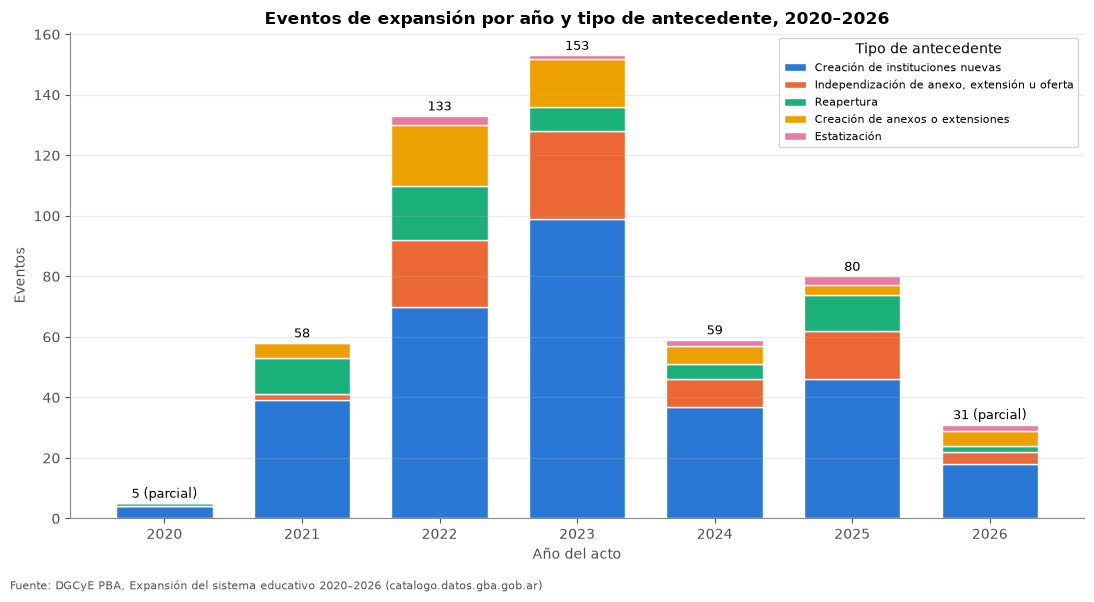

In [10]:
tipos = df_expansion["tipo_antecedente"].value_counts().index
apilado = pd.crosstab(df_expansion["anio"], df_expansion["tipo_antecedente"])[tipos]

fig, ax = plt.subplots(figsize=(11, 6))
base = np.zeros(len(apilado))
for color, tipo in zip(u.PALETA, tipos):
    ax.bar(apilado.index, apilado[tipo], bottom=base, color=color, label=tipo, width=0.7,
           edgecolor="white", linewidth=1)
    base += apilado[tipo].to_numpy()
for anio, total in zip(apilado.index, base):
    etiqueta = f"{int(total)}" + (" (parcial)" if anio in (2020, 2026) else "")
    ax.annotate(etiqueta, (anio, total), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax.set_title("Eventos de expansión por año y tipo de antecedente, 2020–2026")
ax.set_xlabel("Año del acto")
ax.set_ylabel("Eventos")
ax.set_xticks(apilado.index)
ax.legend(title="Tipo de antecedente", fontsize=8)
ax.grid(axis="x", visible=False)
u.guardar_figura(fig, "03_eventos_anio_tipo", FUENTE)
plt.show()

Desagregación del pico 2022–2023 por tipo de antecedente: qué parte de cada tipo cae en esos dos años.

In [11]:
en_pico = df_expansion["anio"].isin([2022, 2023])
df_pico = pd.DataFrame({
    "eventos_2022_2023": df_expansion[en_pico]["tipo_antecedente"].value_counts(),
    "eventos_total": df_expansion["tipo_antecedente"].value_counts(),
})
df_pico["pct_en_pico"] = (df_pico["eventos_2022_2023"] / df_pico["eventos_total"] * 100).round(1)
df_pico["pct_del_pico"] = (df_pico["eventos_2022_2023"] / en_pico.sum() * 100).round(1)
df_pico = df_pico.sort_values("eventos_total", ascending=False)
u.guardar_tabla(df_pico, "03_pico_2022_2023_por_tipo")
print("Eventos en 2022–2023:", en_pico.sum(), f"({en_pico.mean() * 100:.1f} % del total)")
df_pico

Eventos en 2022–2023: 286 (55.1 % del total)


,eventos_2022_2023,eventos_total,pct_en_pico,pct_del_pico
tipo_antecedente,,,,
Creación de instituciones nuevas,169,313,54.0,59.1
"Independización de anexo, extensión u oferta",51,82,62.2,17.8
Reapertura,26,58,44.8,9.1
Creación de anexos o extensiones,36,55,65.5,12.6
Estatización,4,11,36.4,1.4


<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-pico -->
**El pico 2022–2023 combina varios tipos.** En esos dos años hay 286 eventos, el 55,1 % del total. Las creaciones explican el volumen (169 eventos, 59,1 % del pico), y las independizaciones y anexos son los que más se concentran en esos dos años: el 62,2 % de todas las independizaciones y el 65,5 % de todos los anexos caen en el pico, contra el 54,0 % de las creaciones. Las reaperturas están más repartidas en el período (44,8 % en el pico).

Tipo de organización (top 10; el resto se agrupa en "Otros").

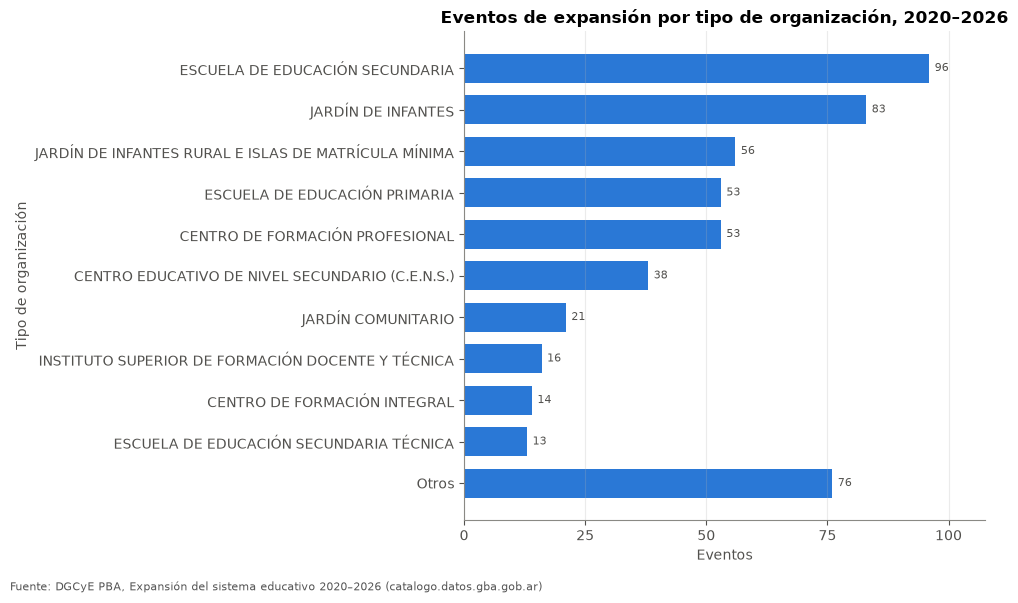

In [12]:
organizacion = df_expansion["tipo_organizacion"].value_counts()
organizacion_top = pd.concat([organizacion.head(10), pd.Series({"Otros": organizacion.iloc[10:].sum()})])
u.guardar_tabla(organizacion.to_frame("eventos"), "03_eventos_tipo_organizacion")
u.grafico_barras_h(organizacion_top, "Eventos de expansión por tipo de organización, 2020–2026",
                   "Eventos", "Tipo de organización", "03_eventos_tipo_organizacion", FUENTE)
plt.show()

Ámbito: eventos de expansión frente a establecimientos únicos del padrón (bases distintas, aclaradas en la tabla).

In [13]:
def es_rural(serie):
    return serie.str.startswith("Rural")

padron_establecimientos = df_padron_analisis.drop_duplicates("establecimiento_id")
df_ambito = pd.DataFrame({
    "eventos_expansion": df_expansion["ambito"].value_counts(),
    "establecimientos_padron": padron_establecimientos["ambito"].value_counts(),
}).fillna(0).astype(int)
df_ambito["pct_eventos"] = (df_ambito["eventos_expansion"] / df_ambito["eventos_expansion"].sum() * 100).round(1)
df_ambito["pct_establecimientos_padron"] = (
    df_ambito["establecimientos_padron"] / df_ambito["establecimientos_padron"].sum() * 100
).round(1)
u.guardar_tabla(df_ambito, "03_ambito_expansion_vs_padron")
display(df_ambito)

pct_rural_eventos = es_rural(df_expansion["ambito"]).mean() * 100
pct_rural_padron = es_rural(padron_establecimientos["ambito"]).mean() * 100
print(f"Rural: {pct_rural_eventos:.1f} % de los eventos contra {pct_rural_padron:.1f} % de los establecimientos del padrón")

,eventos_expansion,establecimientos_padron,pct_eventos,pct_establecimientos_padron
ambito,,,,
Itinerante,0,7,0.0,0.0
Rural Agrupado,49,1076,9.4,5.5
Rural Disperso,94,1958,18.1,9.9
Urbano,376,16697,72.4,84.6


Rural: 27.6 % de los eventos contra 15.4 % de los establecimientos del padrón


<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-rural -->
**La expansión es proporcionalmente más rural que el sistema**: el 27,6 % de los eventos son rurales (143 de 519), contra 15,4 % de rurales entre los establecimientos únicos del padrón. Es casi el doble. Las bases son distintas (eventos frente a establecimientos), pero la diferencia es grande y no depende de eso.

In [14]:
df_expansion["tipo_documento"].value_counts().to_frame("eventos")

,eventos
tipo_documento,
Resolución,495
Informe Secretaria de Inspección,16
Otros,4
Memorando,3
Disposición,1


## 3. Territorio

**Unidad: evento.** Para cada municipio se muestran los eventos absolutos y dos tasas: la principal, eventos cada 10.000 alumnos de matrícula del sistema (del 01, sin C.E.F. ni C.E.C.), y la secundaria, eventos cada 100 establecimientos del padrón.
Las tasas con pocos eventos son inestables. No se excluye a nadie: se muestran la cantidad de eventos, la matrícula y un intervalo de confianza aproximado (Poisson, ±1,96·√n), y se clasifica la **base** según la cantidad de eventos: chica (< 3), media (3 a 9) o grande (≥ 10).

In [15]:
def clasificar_base(eventos):
    return pd.cut(eventos, bins=[-1, 2, 9, np.inf], labels=["chica", "media", "grande"])


def tabla_territorial(clave_expansion, clave_padron):
    tabla = pd.DataFrame({
        "eventos": df_expansion.groupby(clave_expansion).size(),
        "matricula_sistema": df_padron_analisis.groupby(clave_padron)["matricula_sistema"].sum(),
        "establecimientos_padron": df_padron_analisis.groupby(clave_padron)["establecimiento_id"].nunique(),
    })
    tabla["eventos"] = tabla["eventos"].fillna(0).astype(int)
    tabla["tasa_10k"] = tabla["eventos"] / tabla["matricula_sistema"] * 10_000
    margen = 1.96 * np.sqrt(tabla["eventos"])
    tabla["tasa_10k_ic_inf"] = ((tabla["eventos"] - margen).clip(lower=0) / tabla["matricula_sistema"] * 10_000)
    tabla["tasa_10k_ic_sup"] = ((tabla["eventos"] + margen) / tabla["matricula_sistema"] * 10_000)
    tabla["tasa_100_establecimientos"] = tabla["eventos"] / tabla["establecimientos_padron"] * 100
    tabla["base"] = clasificar_base(tabla["eventos"])
    tabla["rank_eventos"] = tabla["eventos"].rank(ascending=False, method="min").astype(int)
    tabla["rank_tasa_10k"] = tabla["tasa_10k"].rank(ascending=False, method="min").astype(int)
    tabla["rank_tasa_100_est"] = tabla["tasa_100_establecimientos"].rank(ascending=False, method="min").astype(int)
    return tabla.sort_values("eventos", ascending=False)


df_territorio_municipio = tabla_territorial("municipio_nombre", "municipio_nombre")
u.guardar_tabla(df_territorio_municipio.round(3), "03_municipios_eventos_tasas")

con_eventos = df_territorio_municipio[df_territorio_municipio["eventos"] > 0]
print("Municipios con eventos:", len(con_eventos), "| sin eventos:", (df_territorio_municipio["eventos"] == 0).sum())
print("Base de los municipios con eventos:", con_eventos["base"].value_counts().to_dict())

Municipios con eventos: 115 | sin eventos: 20
Base de los municipios con eventos: {'media': 64, 'chica': 41, 'grande': 10}


In [16]:
columnas = ["eventos", "matricula_sistema", "establecimientos_padron", "tasa_10k", "tasa_10k_ic_inf",
            "tasa_10k_ic_sup", "tasa_100_establecimientos", "base"]
print("Top 15 por eventos absolutos")
display(con_eventos.head(15)[columnas].round(2))
print("Top 15 por eventos cada 10.000 alumnos")
display(con_eventos.sort_values("tasa_10k", ascending=False).head(15)[columnas].round(2))

Top 15 por eventos absolutos


,eventos,matricula_sistema,establecimientos_padron,tasa_10k,tasa_10k_ic_inf,tasa_10k_ic_sup,tasa_100_establecimientos,base
municipio_nombre,,,,,,,,
La Matanza,37,411743,1206,0.9,0.61,1.19,3.07,grande
Lomas de Zamora,32,197426,663,1.62,1.06,2.18,4.83,grande
Almirante Brown,23,150665,505,1.53,0.9,2.15,4.55,grande
San Vicente,19,33656,111,5.65,3.11,8.18,17.12,grande
Berazategui,12,102798,337,1.17,0.51,1.83,3.56,grande
La Plata,12,237803,850,0.5,0.22,0.79,1.41,grande
Pilar,10,120972,351,0.83,0.31,1.34,2.85,grande
Mar Chiquita,10,9134,75,10.95,4.16,17.73,13.33,grande
Ezeiza,10,65087,181,1.54,0.58,2.49,5.52,grande


Top 15 por eventos cada 10.000 alumnos


,eventos,matricula_sistema,establecimientos_padron,tasa_10k,tasa_10k_ic_inf,tasa_10k_ic_sup,tasa_100_establecimientos,base
municipio_nombre,,,,,,,,
General Guido,4,884,26,45.25,0.9,89.59,15.38,media
Pila,5,1407,34,35.54,4.39,66.69,14.71,media
Tordillo,2,639,14,31.3,0.0,74.68,14.29,chica
Lezama,4,1829,28,21.87,0.44,43.3,14.29,media
Castelli,5,2474,35,20.21,2.5,37.93,14.29,media
Alberti,6,3183,43,18.85,3.77,33.93,13.95,media
Pellegrini,3,2080,24,14.42,0.0,30.74,12.50,media
San Cayetano,3,2391,24,12.55,0.0,26.75,12.50,media
Carlos Tejedor,4,3298,59,12.13,0.24,24.01,6.78,media


In [17]:
correlacion_tasas = con_eventos[["tasa_10k", "tasa_100_establecimientos"]].corr(method="spearman").iloc[0, 1]
top10_en_comun = len(
    set(con_eventos["tasa_10k"].nlargest(10).index) & set(con_eventos["tasa_100_establecimientos"].nlargest(10).index)
)
print(f"Spearman entre las dos tasas: {correlacion_tasas:.2f} | municipios en común en el top 10: {top10_en_comun}")

Spearman entre las dos tasas: 0.90 | municipios en común en el top 10: 8


<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-territorio -->
Por eventos absolutos encabezan los municipios grandes del conurbano: La Matanza (37), Lomas de Zamora (32), Almirante Brown (23) y San Vicente (19).
**El ranking por tasa lo encabezan municipios chicos** (General Guido: 4 eventos, 884 alumnos). La tasa es inestable con denominadores chicos, como muestran los intervalos de confianza, y no debe leerse como "mayor expansión relativa" sin considerar el tamaño.
Las dos tasas (por 10.000 alumnos y por 100 establecimientos) dan rankings casi idénticos (Spearman ≈0,90 en los 115 municipios con eventos; 8 municipios se repiten en los dos top 10).

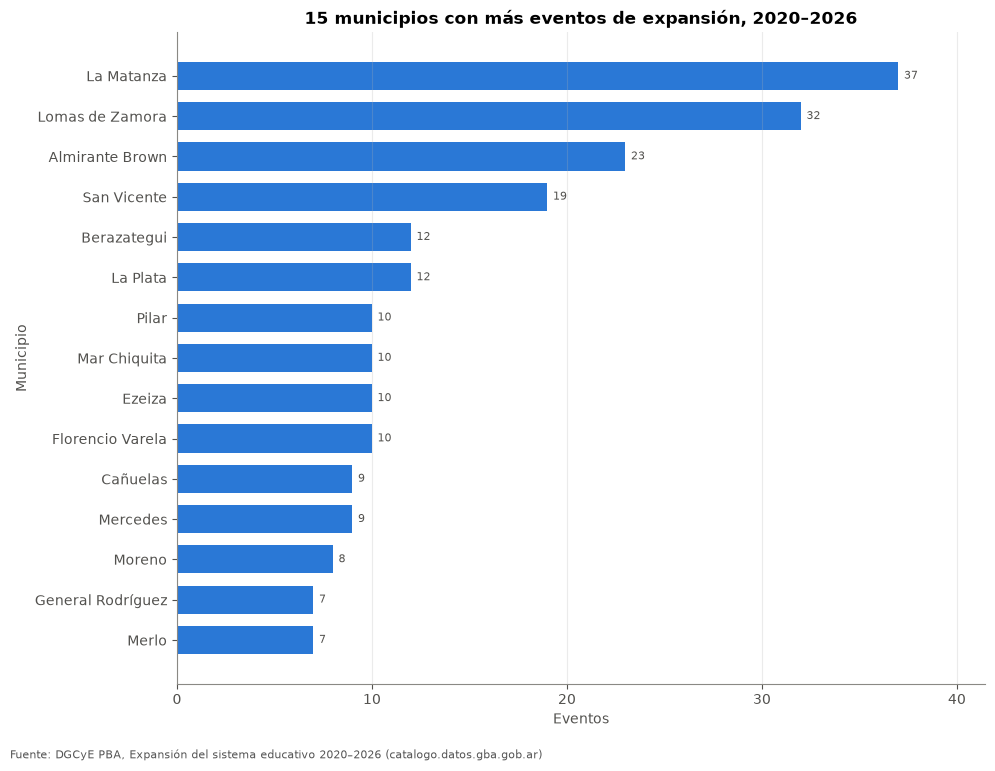

In [18]:
u.grafico_barras_h(con_eventos["eventos"].head(15), "15 municipios con más eventos de expansión, 2020–2026",
                   "Eventos", "Municipio", "03_top15_municipios_eventos", FUENTE)
plt.show()

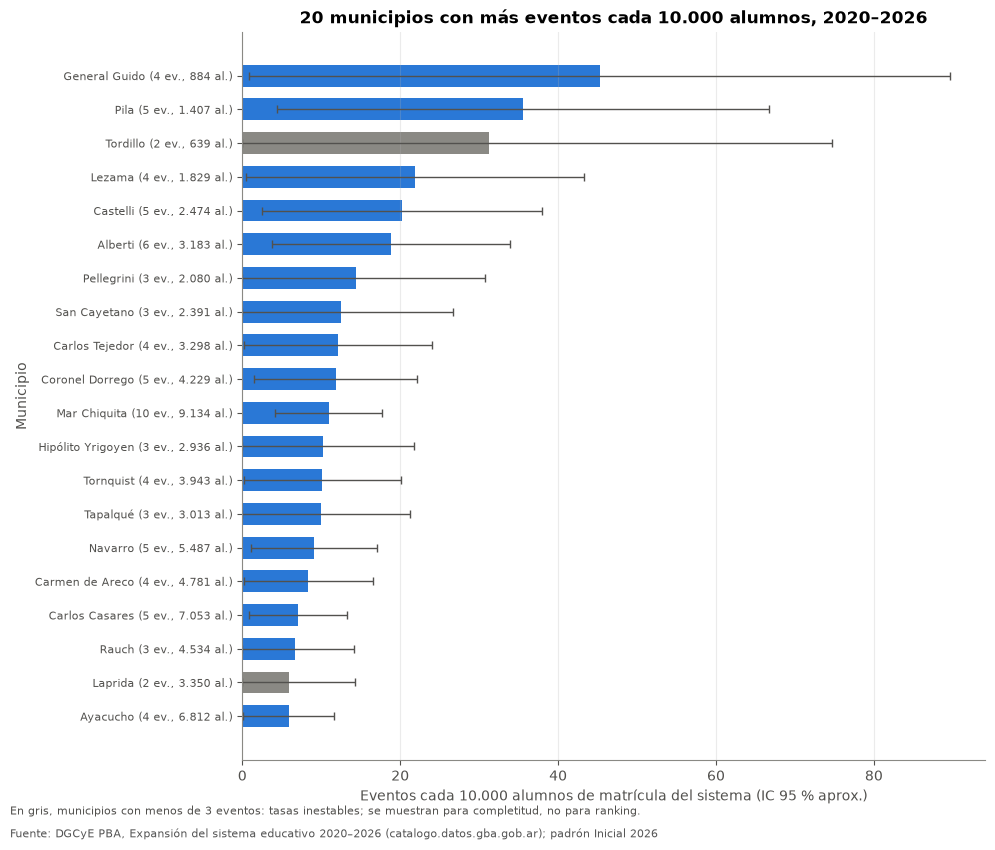

In [19]:
top_tasa = con_eventos.sort_values("tasa_10k", ascending=False).head(20).iloc[::-1]
colores = [u.GRIS if base == "chica" else u.PALETA[0] for base in top_tasa["base"]]

fig, ax = plt.subplots(figsize=(10, 8.5))
posiciones = np.arange(len(top_tasa))
ax.barh(posiciones, top_tasa["tasa_10k"], color=colores, height=0.65)
ax.errorbar(top_tasa["tasa_10k"], posiciones,
            xerr=[top_tasa["tasa_10k"] - top_tasa["tasa_10k_ic_inf"], top_tasa["tasa_10k_ic_sup"] - top_tasa["tasa_10k"]],
            fmt="none", ecolor=u.TEXTO_SECUNDARIO, elinewidth=1, capsize=3)
etiquetas = [f"{m} ({int(e)} ev., {u._miles_ar(mat)} al.)"
             for m, e, mat in zip(top_tasa.index, top_tasa["eventos"], top_tasa["matricula_sistema"])]
ax.set_yticks(posiciones, etiquetas, fontsize=8)
ax.set_title("20 municipios con más eventos cada 10.000 alumnos, 2020–2026")
ax.set_xlabel("Eventos cada 10.000 alumnos de matrícula del sistema (IC 95 % aprox.)")
ax.set_ylabel("Municipio")
ax.grid(axis="y", visible=False)
fig.text(0.01, 0.035, "En gris, municipios con menos de 3 eventos: tasas inestables; se muestran para completitud, no para ranking.",
         fontsize=8, color=u.TEXTO_SECUNDARIO)
u.guardar_figura(fig, "03_top20_municipios_tasa", FUENTE_CRUCE_01)
plt.show()

Regiones educativas (25): eventos absolutos y tasas, con la misma lógica.

,eventos,matricula_sistema,establecimientos_padron,tasa_10k,tasa_10k_ic_inf,tasa_10k_ic_sup,tasa_100_establecimientos,base
region_numero,,,,,,,,
Región 5,57,375634,1122,1.52,1.12,1.91,5.08,grande
Región 2,41,414313,1453,0.99,0.69,1.29,2.82,grande
Región 10,40,179965,863,2.22,1.53,2.91,4.63,grande
Región 3,37,411743,1206,0.9,0.61,1.19,3.07,grande
Región 4,28,400535,1215,0.7,0.44,0.96,2.30,grande
Región 18,27,85355,524,3.16,1.97,4.36,5.15,grande
Región 15,26,73278,565,3.55,2.18,4.91,4.60,grande
Región 17,22,39048,372,5.63,3.28,7.99,5.91,grande
Región 1,22,311828,1216,0.71,0.41,1.0,1.81,grande


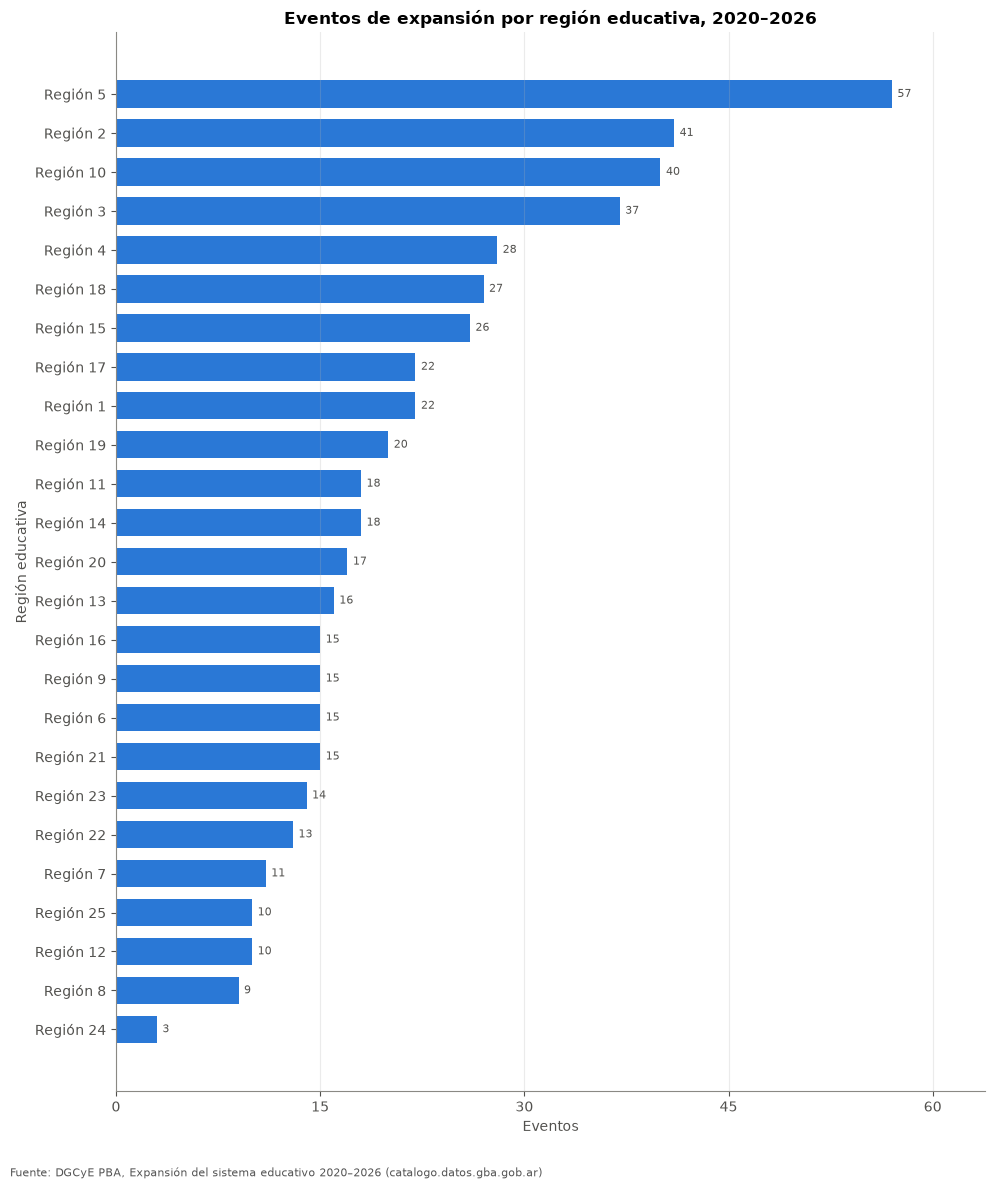

In [20]:
df_territorio_region = tabla_territorial("region_numero", "region_numero")
df_territorio_region.index = "Región " + df_territorio_region.index.astype(str)
u.guardar_tabla(df_territorio_region.round(3), "03_regiones_eventos_tasas")
display(df_territorio_region[columnas].round(2))

u.grafico_barras_h(df_territorio_region["eventos"], "Eventos de expansión por región educativa, 2020–2026",
                   "Eventos", "Región educativa", "03_regiones_eventos", FUENTE)
plt.show()

Mapa: un punto por evento, coloreado por tipo de antecedente, sobre los establecimientos del padrón (en gris).

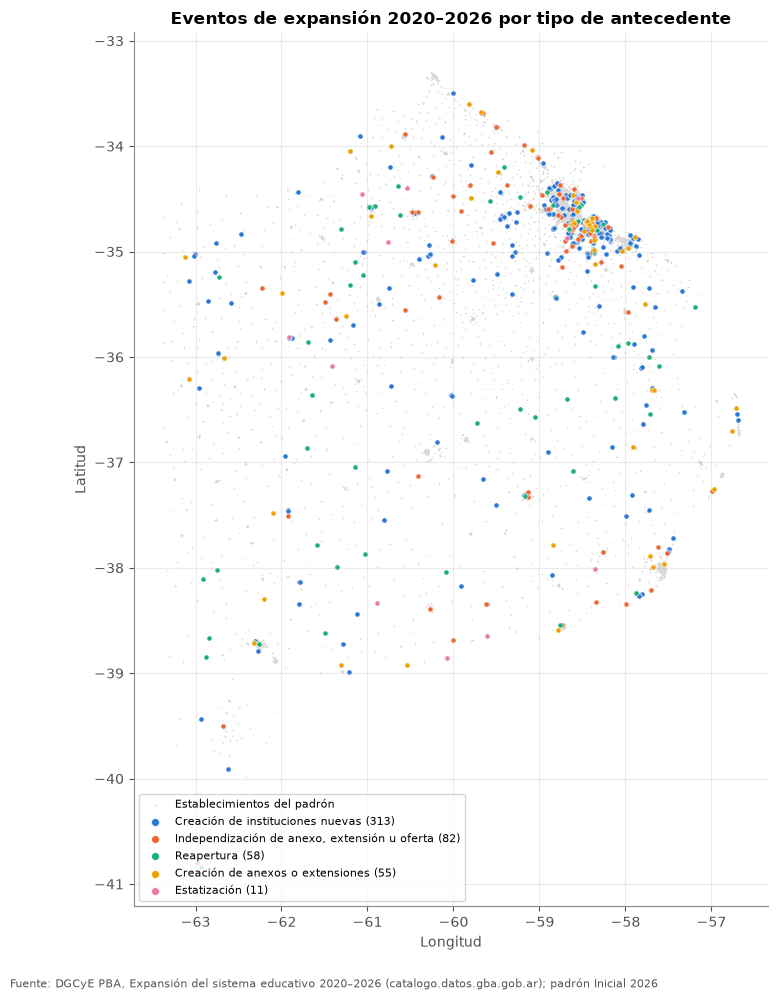

In [21]:
fondo = df_padron_analisis.drop_duplicates("establecimiento_id")

fig, ax = plt.subplots(figsize=(9, 10))
ax.scatter(fondo["longitud"], fondo["latitud"], s=1, color="#d9d8d4", linewidths=0, label="Establecimientos del padrón")
for color, tipo in zip(u.PALETA, tipos):
    grupo = df_expansion[df_expansion["tipo_antecedente"] == tipo]
    ax.scatter(grupo["longitud"], grupo["latitud"], s=14, color=color, edgecolors="white", linewidths=0.4,
               label=f"{tipo} ({len(grupo)})")
ax.set_aspect(1 / np.cos(np.deg2rad(fondo["latitud"].mean())))
ax.set_title("Eventos de expansión 2020–2026 por tipo de antecedente")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
leyenda = ax.legend(loc="lower left", fontsize=8, markerscale=1.5)
u.guardar_figura(fig, "03_mapa_eventos", FUENTE_CRUCE_01)
plt.show()

## 4. Cruce con el padrón (notebook 01)

Cruce por `cueanexo` contra el padrón completo, con periodo "Inicial 2026" y "Nueva". `clave`, `establecimiento_id` y `cui` se usan como validación. **Unidad: evento.**

In [22]:
cueanexo_inicial = set(df_padron.loc[df_padron["periodo"] == "Inicial 2026", "cueanexo"])
cueanexo_nueva = set(df_padron.loc[df_padron["periodo"] == "Nueva", "cueanexo"])

df_expansion["estado_padron"] = np.select(
    [df_expansion["cueanexo"].isin(cueanexo_inicial), df_expansion["cueanexo"].isin(cueanexo_nueva)],
    ["Inicial 2026 (con matrícula)", "Nueva (sin matrícula)"],
    default="Sin par en el padrón",
)
assert not (df_expansion["cueanexo"].isin(cueanexo_inicial) & df_expansion["cueanexo"].isin(cueanexo_nueva)).any()
display(df_expansion["estado_padron"].value_counts().to_frame("eventos"))

for columna in ["clave", "establecimiento_id", "cui"]:
    valores_padron = set(df_padron[columna].astype(str))
    print(f"Eventos cuyo {columna} está en el padrón:", df_expansion[columna].astype(str).isin(valores_padron).sum())

par_id = df_expansion.merge(df_padron.drop_duplicates("cueanexo")[["cueanexo", "establecimiento_id"]],
                            on="cueanexo", suffixes=("", "_padron"))
print("Con par por cueanexo y mismo establecimiento_id:", (par_id["establecimiento_id"] == par_id["establecimiento_id_padron"]).sum(),
      "de", len(par_id))

,eventos
estado_padron,
Inicial 2026 (con matrícula),493
Nueva (sin matrícula),24
Sin par en el padrón,2


Eventos cuyo clave está en el padrón: 517
Eventos cuyo establecimiento_id está en el padrón: 517
Eventos cuyo cui está en el padrón: 518
Con par por cueanexo y mismo establecimiento_id: 517 de 517


Los eventos sin par se reportan con una hipótesis cada uno; no se descartan.

In [23]:
# ¿El padrón tiene algún CIIE, con cualquier tipo de organización? Se busca también por nombre.
patron_ciie = r"INVESTIGACI[OÓ]N EDUCATIVA|C\.?I\.?I\.?E"
ciie_en_padron = df_padron[
    df_padron["tipo_organizacion"].str.contains("INVESTIGACI", na=False)
    | df_padron["establecimiento_nombre"].str.contains(patron_ciie, case=False, regex=True, na=False)
]
print("Filas del padrón que son CIIE (por tipo de organización o por nombre):", len(ciie_en_padron))
assert ciie_en_padron.empty, "El padrón tiene algún CIIE: revisar la hipótesis de los eventos sin par"

HIPOTESIS_SIN_PAR = {
    "62432800": "Creación 2022. Es un CIIE, tipo de organización que el padrón no releva. Su CUI sí está en el padrón, "
                "compartido con otros establecimientos: el edificio existe, pero el CIIE no figura como establecimiento. "
                "Verificar con la fuente.",
    "62485300": "Creación 2025. Es un CIIE, tipo de organización que el padrón no releva. Ni su CUI ni su clave están en "
                "el padrón: además puede tratarse de un edificio nuevo todavía no cargado. Verificar con la fuente.",
}
df_sin_par = df_expansion[df_expansion["estado_padron"] == "Sin par en el padrón"][
    ["establecimiento_id", "establecimiento_nombre", "municipio_nombre", "cueanexo", "cui",
     "tipo_organizacion", "tipo_antecedente", "fecha_acto"]
].copy()
df_sin_par["cui_en_padron"] = df_sin_par["cui"].isin(set(df_padron["cui"]))
df_sin_par["por_que_no_cruza"] = df_sin_par["cueanexo"].map(HIPOTESIS_SIN_PAR)
assert df_sin_par["por_que_no_cruza"].notna().all(), "Hay un evento sin par sin hipótesis: revisar"
u.guardar_tabla(df_sin_par, "03_eventos_sin_par_padron", index=False)
df_sin_par

Filas del padrón que son CIIE (por tipo de organización o por nombre): 0


,establecimiento_id,establecimiento_nombre,municipio_nombre,cueanexo,cui,tipo_organizacion,tipo_antecedente,fecha_acto,cui_en_padron,por_que_no_cruza
186,102988,"CENTRO DE INVESTIGACIÓN EDUCATIVA ""MERY MOURIZ""",Lezama,62432800,613700030,CENTRO DE INVESTIGACIÓN EDUCATIVA,Creación de instituciones nuevas,2022-03-22,True,"Creación 2022. Es un CIIE, tipo de organizació..."
473,103550,"CENTRO DE CAPACITACIÓN, INFORMACIÓN E INVESTIG...",Alberti,62485300,600300323,CENTRO DE INVESTIGACIÓN EDUCATIVA,Creación de instituciones nuevas,2025-08-05,False,"Creación 2025. Es un CIIE, tipo de organizació..."


<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-sin-par -->
**517 de los 519 eventos tienen par en el padrón.** Los 2 sin par son Centros de Investigación Educativa (CIIE) de Lezama y Alberti. Ese tipo de organización no aparece en el padrón: no hay ningún CIIE ni por tipo de organización ni por nombre. La hipótesis de que el padrón no releva los CIIE como establecimiento se sostiene. Ninguno de los dos es posterior al corte del padrón (19/10/2026), así que el corte no explica la falta de par. Quedan como limitación para el informe de síntesis.

Eventos que en el padrón figuran como ofertas "Nueva".

In [24]:
df_eventos_nueva = df_expansion[df_expansion["estado_padron"] == "Nueva (sin matrícula)"]
print("Eventos:", len(df_eventos_nueva), "| establecimientos únicos:", df_eventos_nueva["establecimiento_id"].nunique())
display(pd.crosstab(df_eventos_nueva["tipo_antecedente"], df_eventos_nueva["anio"], margins=True, margins_name="Total"))

eventos_2026 = (df_expansion["anio"] == 2026).sum()
print(f"Eventos de 2026: {eventos_2026}; de ellos en 'Nueva': {(df_eventos_nueva['anio'] == 2026).sum()}")

df_nueva_2023 = df_eventos_nueva[df_eventos_nueva["anio"] == 2023][
    ["establecimiento_id", "establecimiento_nombre", "municipio_nombre", "tipo_antecedente", "fecha_acto", "ambito"]
]
u.guardar_tabla(df_eventos_nueva, "03_eventos_ofertas_nueva", index=False)
u.guardar_tabla(df_nueva_2023, "03_nueva_2023_sin_matricula", index=False)
df_nueva_2023

Eventos: 24 | establecimientos únicos: 24


anio,2023,2025,2026,Total
tipo_antecedente,,,,
Creación de anexos o extensiones,0,0,4,4
Creación de instituciones nuevas,3,3,9,15
Estatización,0,1,0,1
"Independización de anexo, extensión u oferta",0,0,3,3
Reapertura,0,1,0,1
Total,3,5,16,24


Eventos de 2026: 31; de ellos en 'Nueva': 16


,establecimiento_id,establecimiento_nombre,municipio_nombre,tipo_antecedente,fecha_acto,ambito
95,64091,ESCUELA DE EDUCACIÓN PRIMARIA N°99,Lomas de Zamora,Creación de instituciones nuevas,2023-10-31,Urbano
344,103297,CENTRO DE FORMACIÓN PROFESIONAL N°404,San Miguel,Creación de instituciones nuevas,2023-09-20,Urbano
355,103319,CENTRO DE FORMACIÓN LABORAL Nº405,Florencio Varela,Creación de instituciones nuevas,2023-10-31,Urbano


<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-nueva -->
**24 de los eventos de expansión corresponden a ofertas "Nueva" en el padrón: ya existen como oferta, pero no tienen matrícula asignada al corte.** Son 24 establecimientos distintos (15 creaciones, 4 anexos, 3 independizaciones, 1 reapertura y 1 estatización). Por año del acto, 16 son de 2026 (la mitad de los 31 eventos de 2026), 5 de 2025 y 3 de 2023.
**Tres ofertas creadas en 2023 siguen sin matrícula asignada al corte de 2026, casi tres años después: la Escuela de Educación Primaria N°99 (Lomas de Zamora), el Centro de Formación Profesional N°404 (San Miguel) y el Centro de Formación Laboral Nº405 (Florencio Varela).** También están en `outputs/03_nueva_2023_sin_matricula.csv`.

Matrícula actual (padrón Inicial 2026, matrícula del sistema) de los establecimientos con eventos, según el año del acto.
**Unidad: establecimiento único.** El 102873, que tiene dos actos, se cuenta una sola vez, en el año de su primer acto (2021). La matrícula de cada establecimiento es la suma de sus ofertas con el mismo `cueanexo`.

In [25]:
matricula_por_cueanexo = df_padron_analisis.groupby("cueanexo")["matricula_sistema"].sum()

df_establecimientos_expansion = (
    df_expansion.sort_values("fecha_acto")
    .drop_duplicates("establecimiento_id")
    [["establecimiento_id", "cueanexo", "municipio_nombre", "anio", "tipo_antecedente", "estado_padron"]]
    .copy()
)
df_establecimientos_expansion["matricula_sistema_2026"] = df_establecimientos_expansion["cueanexo"].map(matricula_por_cueanexo)

df_matricula_por_anio_acto = df_establecimientos_expansion.groupby("anio").agg(
    establecimientos=("establecimiento_id", "size"),
    con_matricula=("estado_padron", lambda s: (s == "Inicial 2026 (con matrícula)").sum()),
    en_nueva=("estado_padron", lambda s: (s == "Nueva (sin matrícula)").sum()),
    sin_par=("estado_padron", lambda s: (s == "Sin par en el padrón").sum()),
    matricula_sistema_2026=("matricula_sistema_2026", "sum"),
    mediana_por_establecimiento=("matricula_sistema_2026", "median"),
)
u.guardar_tabla(df_matricula_por_anio_acto, "03_matricula_2026_por_anio_acto")
print("Establecimientos únicos:", len(df_establecimientos_expansion))
df_matricula_por_anio_acto

Establecimientos únicos: 518


,establecimientos,con_matricula,en_nueva,sin_par,matricula_sistema_2026,mediana_por_establecimiento
anio,,,,,,
2020,5,5,0,0,438,90.0
2021,57,57,0,0,7314,96.0
2022,133,132,0,1,15293,97.5
2023,153,150,3,0,18507,59.5
2024,59,59,0,0,7431,75.0
2025,80,74,5,1,9329,98.0
2026,31,15,16,0,1168,76.0


## 5. Cruce con la serie de matrícula (notebook 02)

Por municipio: intensidad de la expansión (eventos absolutos y cada 10.000 alumnos) frente a la variación de la matrícula en la serie 2015–2025.

<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-ventanas -->
**La ventana principal es 2020→2025 porque es el tramo en que las dos fuentes se superponen. La ventana 2015→2025 se incluye como secundaria solo para comparar con el análisis del 02; no debe leerse como "efecto de la expansión sobre la matrícula", porque 2015–2019 no tiene eventos registrados en este archivo.**

**La correlación es descriptiva, no causal: los eventos de expansión y el crecimiento de matrícula pueden estar influidos por factores que no están en estos datos (demografía, políticas, migración).**

Se incluyen los 115 municipios con eventos; los 20 sin eventos se informan aparte. Spearman se calcula con `DataFrame.corr`.

In [26]:
df_serie = u.cargar_matricula_municipios()
serie_pivot = df_serie.pivot(index="municipio_nombre", columns="anio", values="matricula")
variacion_serie = pd.DataFrame({
    "variacion_2020_2025_pct": (serie_pivot[2025] / serie_pivot[2020] - 1) * 100,
    "cambio_2020_2025": serie_pivot[2025] - serie_pivot[2020],
    "variacion_2015_2025_pct": (serie_pivot[2025] / serie_pivot[2015] - 1) * 100,
})

sin_par_serie = set(df_territorio_municipio.index) ^ set(variacion_serie.index)
print("Municipios sin par entre padrón y serie (después de normalizar):", sorted(sin_par_serie) or "ninguno")

df_cruce_02 = df_territorio_municipio.join(variacion_serie, validate="one_to_one")
df_cruce_02["rank_variacion_2020_2025"] = df_cruce_02["variacion_2020_2025_pct"].rank(ascending=False, method="min").astype(int)
con_eventos_02 = df_cruce_02[df_cruce_02["eventos"] > 0]
sin_eventos_02 = df_cruce_02[df_cruce_02["eventos"] == 0]
u.guardar_tabla(df_cruce_02.round(3), "03_cruce_serie_02")

df_correlaciones = pd.DataFrame({
    ventana: {
        medida: con_eventos_02[[medida, ventana]].corr(method="spearman").iloc[0, 1]
        for medida in ["tasa_10k", "eventos"]
    }
    for ventana in ["variacion_2020_2025_pct", "variacion_2015_2025_pct"]
}).round(3)
# Referencia: misma correlación incluyendo los 20 municipios sin eventos (tasa 0)
df_correlaciones.loc["tasa_10k_con_sin_eventos"] = [
    df_cruce_02[["tasa_10k", ventana]].corr(method="spearman").iloc[0, 1]
    for ventana in ["variacion_2020_2025_pct", "variacion_2015_2025_pct"]
]
df_correlaciones = df_correlaciones.round(3)
df_correlaciones.index = ["eventos cada 10.000 alumnos (115 con eventos)", "eventos absolutos (115 con eventos)",
                          "eventos cada 10.000 alumnos (135, incluye 20 sin eventos)"]
df_correlaciones.columns = ["2020→2025 (principal)", "2015→2025 (secundaria)"]
u.guardar_tabla(df_correlaciones, "03_correlaciones_spearman")
display(df_correlaciones)

Municipios sin par entre padrón y serie (después de normalizar): ninguno


,2020→2025 (principal),2015→2025 (secundaria)
eventos cada 10.000 alumnos (115 con eventos),0.365,0.203
eventos absolutos (115 con eventos),-0.024,-0.019
"eventos cada 10.000 alumnos (135, incluye 20 sin eventos)",0.251,0.178


¿Por qué la correlación baja al incluir los 20 municipios sin eventos? Se compara el crecimiento de los dos grupos y se mira si la expansión se asocia con el crecimiento **previo** (2015→2020).

In [27]:
df_cruce_02["variacion_2015_2020_pct"] = (serie_pivot[2020] / serie_pivot[2015] - 1) * 100
con_eventos_02 = df_cruce_02[df_cruce_02["eventos"] > 0]
sin_eventos_02 = df_cruce_02[df_cruce_02["eventos"] == 0]

df_grupos_expansion = pd.DataFrame({
    grupo: {
        "municipios": len(tabla),
        "variacion_2020_2025_media": tabla["variacion_2020_2025_pct"].mean(),
        "variacion_2020_2025_mediana": tabla["variacion_2020_2025_pct"].median(),
        "variacion_2015_2020_media": tabla["variacion_2015_2020_pct"].mean(),
    }
    for grupo, tabla in [("con eventos", con_eventos_02), ("sin eventos", sin_eventos_02)]
}).T.round(2)
u.guardar_tabla(df_grupos_expansion, "03_crecimiento_con_sin_eventos")
display(df_grupos_expansion)

correlacion_previa = con_eventos_02[["tasa_10k", "variacion_2015_2020_pct"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman entre eventos cada 10.000 alumnos y variación previa 2015→2020 (115 municipios): {correlacion_previa:.3f}")

,municipios,variacion_2020_2025_media,variacion_2020_2025_mediana,variacion_2015_2020_media
con eventos,115.0,0.02,-1.16,4.63
sin eventos,20.0,0.55,-1.14,1.81


Spearman entre eventos cada 10.000 alumnos y variación previa 2015→2020 (115 municipios): -0.031


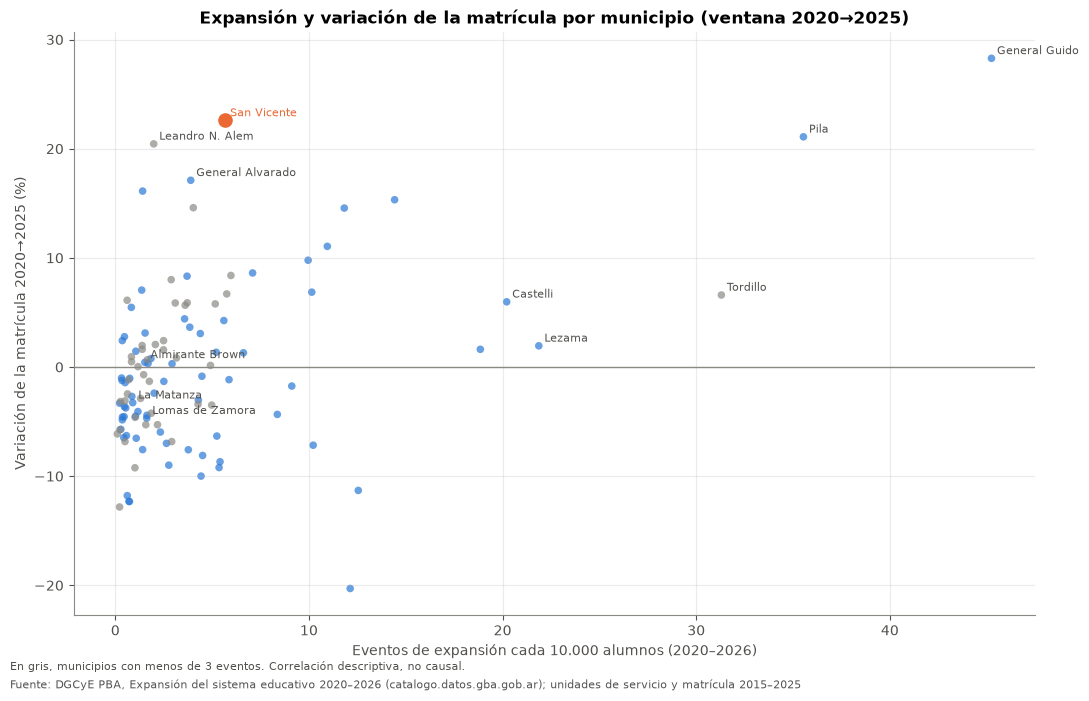

In [28]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(con_eventos_02["tasa_10k"], con_eventos_02["variacion_2020_2025_pct"], s=30, alpha=0.7,
           color=[u.GRIS if b == "chica" else u.PALETA[0] for b in con_eventos_02["base"]], linewidths=0)
ax.axhline(0, color=u.GRIS, linewidth=1)

destacados = set(con_eventos_02["tasa_10k"].nlargest(5).index) | set(con_eventos_02["variacion_2020_2025_pct"].nlargest(5).index) \
    | set(con_eventos_02["eventos"].nlargest(3).index) | {"San Vicente"}
for municipio in destacados:
    fila = con_eventos_02.loc[municipio]
    color = u.PALETA[1] if municipio == "San Vicente" else u.TEXTO_SECUNDARIO
    ax.annotate(municipio, (fila["tasa_10k"], fila["variacion_2020_2025_pct"]), xytext=(4, 3),
                textcoords="offset points", fontsize=8, color=color)
fila_sv = con_eventos_02.loc["San Vicente"]
ax.scatter([fila_sv["tasa_10k"]], [fila_sv["variacion_2020_2025_pct"]], s=90, color=u.PALETA[1], zorder=3)

ax.set_title("Expansión y variación de la matrícula por municipio (ventana 2020→2025)")
ax.set_xlabel("Eventos de expansión cada 10.000 alumnos (2020–2026)")
ax.set_ylabel("Variación de la matrícula 2020→2025 (%)")
fig.text(0.01, 0.035, "En gris, municipios con menos de 3 eventos. Correlación descriptiva, no causal.",
         fontsize=8, color=u.TEXTO_SECUNDARIO)
u.guardar_figura(fig, "03_expansion_vs_matricula", FUENTE_CRUCE_02)
plt.show()

<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-correlacion -->
**La asociación entre eventos de expansión cada 10.000 alumnos y la variación de matrícula 2020→2025 es débil a moderada (Spearman ≈0,36 en los 115 municipios con eventos).** Es una asociación real, no ruido, pero no es fuerte: no alcanza para decir que la expansión explique el crecimiento.

Si se incluyen los 20 municipios sin eventos, baja a ≈0,25. La baja no se debe a que esos municipios crezcan menos: su variación 2020→2025 es similar a la de los municipios con eventos (media +0,55 % contra +0,02 %; mediana −1,14 % contra −1,16 %). Lo que pasa es que entran todos con tasa 0 y con un crecimiento repartido como el del resto, y eso diluye la asociación. Tampoco hay asociación entre la intensidad de la expansión y el crecimiento previo 2015→2020 (Spearman ≈−0,03), así que estos datos no permiten afirmar que la expansión se haya concentrado donde ya había crecimiento.

**La relación es descriptiva, no causal**: hay factores (demografía, migración, política) que no están en estos datos. Con eventos absolutos la asociación desaparece (≈−0,02), porque los municipios grandes concentran eventos sin crecer más en proporción.

Los municipios con algún evento venían creciendo más antes de 2020 (+4,63 % en 2015→2020 contra +1,81 % en los sin eventos), pero esa diferencia es entre grupos, no según la intensidad de la expansión.

### San Vicente

In [29]:
eventos_sv = df_expansion[df_expansion["municipio_nombre"] == "San Vicente"]
print("Eventos:", len(eventos_sv), "| establecimientos únicos:", eventos_sv["establecimiento_id"].nunique())
print("Tipo de antecedente:", eventos_sv["tipo_antecedente"].value_counts().to_dict())
print("Ámbito:", eventos_sv["ambito"].value_counts().to_dict())
print("Tipo de organización:", eventos_sv["tipo_organizacion"].value_counts().to_dict())
print("Por año:", eventos_sv["anio"].value_counts().sort_index().to_dict())

fila_sv = df_cruce_02.loc["San Vicente"]
matricula_establecimientos_sv = df_establecimientos_expansion.loc[
    df_establecimientos_expansion["municipio_nombre"] == "San Vicente", "matricula_sistema_2026"
].sum()
display(fila_sv[["eventos", "rank_eventos", "rank_tasa_100_est", "rank_tasa_10k", "variacion_2015_2025_pct",
                 "variacion_2020_2025_pct", "cambio_2020_2025", "rank_variacion_2020_2025"]].to_frame("San Vicente"))
print("Matrícula del sistema 2026 de los establecimientos con eventos:", matricula_establecimientos_sv)

Eventos: 19 | establecimientos únicos: 18
Tipo de antecedente: {'Creación de instituciones nuevas': 15, 'Creación de anexos o extensiones': 2, 'Reapertura': 1, 'Independización de anexo, extensión u oferta': 1}
Ámbito: {'Urbano': 17, 'Rural Disperso': 2}
Tipo de organización: {'JARDÍN DE INFANTES': 6, 'ESCUELA DE EDUCACIÓN PRIMARIA': 5, 'ESCUELA DE EDUCACIÓN SECUNDARIA': 2, 'JARDÍN DE INFANTES RURAL E ISLAS DE MATRÍCULA MÍNIMA': 1, 'CENTRO DE EDUCACIÓN AGRARIA': 1, 'INSTITUTO SUPERIOR DE FORMACIÓN DOCENTE Y TÉCNICA': 1, 'CENTRO DE ESTIMULACIÓN Y APRENDIZAJES TEMPRANOS': 1, 'ESCUELA DE EDUCACIÓN ESPECIAL': 1, 'ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA': 1}
Por año: {2021: 5, 2022: 7, 2023: 2, 2025: 3, 2026: 2}


,San Vicente
eventos,19
rank_eventos,4
rank_tasa_100_est,1
rank_tasa_10k,22
variacion_2015_2025_pct,36.04019
variacion_2020_2025_pct,22.587838
cambio_2020_2025,6686
rank_variacion_2020_2025,2


Matrícula del sistema 2026 de los establecimientos con eventos: 3318


<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-san-vicente -->
**San Vicente** tiene 19 eventos (18 establecimientos, por el 102873): 15 creaciones, 2 anexos, 1 reapertura y 1 independización. 17 son urbanos y 2 rurales; predominan los jardines (6) y las primarias (5). Es 4º en eventos absolutos, 1º en eventos cada 100 establecimientos y 22º en eventos cada 10.000 alumnos: tiene mucha expansión para su cantidad de escuelas, pero no tanta para su matrícula.
En el 02 su matrícula creció +36,04 % entre 2015 y 2025; en la ventana principal 2020→2025 creció +22,6 % (+6.686 alumnos), el 2º mayor crecimiento de la provincia.
Los establecimientos con eventos en San Vicente suman unos 3.318 alumnos en el padrón 2026 (cada establecimiento contado una vez). No es comparable con el +6.686 de la serie 2020→2025 porque son mediciones distintas (foto frente a serie anual), pero da un orden de magnitud: la expansión explica una parte del crecimiento, no todo.

<!-- verificado 2026-10-21, hash datos: exp=c3cc336;padron=d62f13c;serie=62c8e36, id: md-casos -->
## 6. Casos candidatos para el informe de síntesis (05)

Solo se identifican; se redactan en el 05.
1. **Calce casi total con el padrón**: 517 de 519 eventos. Los 2 faltantes son CIIE, un tipo de organización que el padrón no releva (limitación).
2. **El pico 2022–2023 combina varios tipos**: las creaciones explican el volumen, y las independizaciones y anexos son los que más se concentran.
3. **La expansión es más rural que el sistema**: 27,6 % de los eventos contra 15,4 % de los establecimientos.
4. **Ofertas creadas sin matrícula**: 24 eventos son ofertas "Nueva"; 3 de 2023 siguen sin matrícula casi tres años después.
5. **San Vicente**: alta expansión para su cantidad de escuelas y 2º mayor crecimiento de matrícula 2020→2025.
6. **Asociación débil a moderada** entre expansión y crecimiento de matrícula a nivel municipio (Spearman ≈0,36): no es nula, pero no alcanza para atribuir el crecimiento a la expansión.

### Eventos por nivel

Para el informe de síntesis (05): agrupa los tipos de organización por nivel según su nombre. Es aproximado: los jardines (de infantes, rurales e islas, comunitarios y maternales) son el nivel inicial; la secundaria incluye los CENS para adultos.

In [30]:
def nivel_por_tipo(tipo):
    if "JARDÍN" in tipo:
        return "Inicial (jardines)"
    if "SECUNDARIA" in tipo or "C.E.N.S." in tipo:
        return "Secundaria"
    if "PRIMARIA" in tipo:
        return "Primaria"
    if "FORMACIÓN" in tipo:
        return "Formación profesional y superior"
    return "Otros"


eventos_nivel = df_expansion["tipo_organizacion"].map(nivel_por_tipo).value_counts()
assert eventos_nivel.sum() == len(df_expansion)
assert eventos_nivel.idxmax() == "Inicial (jardines)", "El nivel con más eventos ya no es el inicial"
u.guardar_tabla(eventos_nivel.to_frame("eventos"), "03_eventos_nivel")
eventos_nivel.to_frame("eventos").assign(pct=(eventos_nivel / len(df_expansion) * 100).round(1))

,eventos,pct
tipo_organizacion,,
Inicial (jardines),170,32.8
Secundaria,152,29.3
Formación profesional y superior,83,16.0
Primaria,66,12.7
Otros,48,9.2


## Cifras para el informe de síntesis

Deja en `outputs/03_cifras_informe.csv` las cifras que usa el informe de síntesis (05). No es análisis nuevo: son valores ya calculados en este notebook.

In [31]:
corr_115 = df_correlaciones.loc["eventos cada 10.000 alumnos (115 con eventos)", "2020→2025 (principal)"]
corr_135 = df_correlaciones.loc["eventos cada 10.000 alumnos (135, incluye 20 sin eventos)", "2020→2025 (principal)"]
df_cifras_informe = u.guardar_cifras_informe([
    ("eventos_total", len(df_expansion), "eventos", "celda 5", "Eventos de expansión 23/04/2020 – 02/09/2026"),
    ("municipios_con_eventos", df_expansion["municipio_nombre"].nunique(), "municipios", "celda 5", "Municipios con al menos un evento"),
    ("eventos_2022", (df_expansion["anio"] == 2022).sum(), "eventos", "celda 20", "Eventos con acto en 2022"),
    ("eventos_2023", (df_expansion["anio"] == 2023).sum(), "eventos", "celda 20", "Eventos con acto en 2023"),
    ("pico_2022_2023_eventos", en_pico.sum(), "eventos", "celda 23", "133 de 2022 + 153 de 2023"),
    ("pico_2022_2023_pct", en_pico.mean() * 100, "%", "celda 23", "Eventos de 2022–2023 sobre el total de 519"),
    ("rural_eventos_pct", pct_rural_eventos, "%", "celda 28",
     "9,4 % rural agrupado + 18,1 % rural disperso; la suma da 27,5 por redondeo, se reporta 27,6 (143 de 519 eventos)"),
    ("rural_padron_pct", pct_rural_padron, "%", "celda 28", "Establecimientos únicos rurales del padrón (5,5 % agrupado + 9,9 % disperso)"),
    ("eventos_con_par_padron", (df_expansion["estado_padron"] != "Sin par en el padrón").sum(), "eventos", "celda 43", "Eventos con par en el padrón por cueanexo"),
    ("eventos_sin_par_padron", len(df_sin_par), "eventos", "celda 45", "Eventos sin par: los 2 CIIE (Lezama 2022, Alberti 2025)"),
    ("eventos_ofertas_nueva", len(df_eventos_nueva), "eventos", "celda 48", "Eventos cuyo establecimiento figura como oferta Nueva (sin matrícula) en el padrón"),
    ("nueva_2023_sin_matricula", len(df_nueva_2023), "ofertas", "celda 48", "Ofertas creadas en 2023 que siguen sin matrícula al corte de 2026"),
    ("municipios_sin_eventos", len(sin_eventos_02), "municipios", "celda 54", "Municipios sin eventos de expansión registrados (de 135)"),
    ("spearman_expansion_matricula_115", corr_115, "Spearman", "celda 54", "Eventos cada 10.000 alumnos vs. variación de matrícula 2020→2025, 115 municipios con eventos"),
    ("spearman_expansion_matricula_135", corr_135, "Spearman", "celda 54", "Ídem, incluyendo los 20 municipios sin eventos (sensibilidad)"),
    ("jardines_eventos", eventos_nivel["Inicial (jardines)"], "eventos", "Eventos por nivel", "Eventos de jardines (de infantes, rurales e islas, comunitarios y maternales)"),
    ("jardines_pct", eventos_nivel["Inicial (jardines)"] / len(df_expansion) * 100, "%", "Eventos por nivel", "Jardines sobre el total de eventos; es el nivel con más eventos"),
    ("secundaria_eventos", eventos_nivel["Secundaria"], "eventos", "Eventos por nivel", "Eventos de secundaria (incluye CENS para adultos), 2º nivel con más eventos"),
], "03")
df_cifras_informe

,cifra_id,valor,unidad,notebook,celda_origen,descripcion
0,eventos_total,519.0000,eventos,03,celda 5,Eventos de expansión 23/04/2020 – 02/09/2026
1,municipios_con_eventos,115.0000,municipios,03,celda 5,Municipios con al menos un evento
2,eventos_2022,133.0000,eventos,03,celda 20,Eventos con acto en 2022
3,eventos_2023,153.0000,eventos,03,celda 20,Eventos con acto en 2023
4,pico_2022_2023_eventos,286.0000,eventos,03,celda 23,133 de 2022 + 153 de 2023
5,pico_2022_2023_pct,55.1060,%,03,celda 23,Eventos de 2022–2023 sobre el total de 519
6,rural_eventos_pct,27.5530,%,03,celda 28,"9,4 % rural agrupado + 18,1 % rural disperso; ..."
7,rural_padron_pct,15.3714,%,03,celda 28,"Establecimientos únicos rurales del padrón (5,..."
8,eventos_con_par_padron,517.0000,eventos,03,celda 43,Eventos con par en el padrón por cueanexo
9,eventos_sin_par_padron,2.0000,eventos,03,celda 45,"Eventos sin par: los 2 CIIE (Lezama 2022, Albe..."


## 7. Control de cifras citadas en los markdown

Igual que en el 01 y el 02: compara las cifras y listas escritas en los markdown marcados con el cálculo. No corrige textos. Con `MODO_ESTRICTO = False` solo reporta. La marca lleva el hash de cada archivo; si alguno cambia, el control indica cuál.

In [32]:
exp = df_expansion
pico = df_pico
tm = df_territorio_municipio
corr = df_correlaciones
sv = df_cruce_02.loc["San Vicente"]
n_tipo_sv = eventos_sv["tipo_antecedente"].value_counts()
n_org_sv = eventos_sv["tipo_organizacion"].value_counts()
n_tipo_nueva = df_eventos_nueva["tipo_antecedente"].value_counts()
n_anio_nueva = df_eventos_nueva["anio"].value_counts()
CREA, INDEP, ANEXO, REAP, ESTAT = (
    "Creación de instituciones nuevas", "Independización de anexo, extensión u oferta",
    "Creación de anexos o extensiones", "Reapertura", "Estatización",
)

citas = [
    # Alcance y calidad
    ("md-alcance", "con 519 eventos", len(exp)),
    ("md-alcance", "en 115 municipios", exp["municipio_nombre"].nunique()),
    ("md-dos-eventos", "El establecimiento 102873", set(df_establecimiento_dos_eventos["establecimiento_id"])),
    # Pico
    ("md-pico", "hay 286 eventos", en_pico.sum()),
    ("md-pico", "el 55,1 % del total", en_pico.mean() * 100),
    ("md-pico", "(169 eventos", pico.loc[CREA, "eventos_2022_2023"]),
    ("md-pico", "59,1 % del pico", pico.loc[CREA, "pct_del_pico"]),
    ("md-pico", "el 62,2 % de todas las independizaciones", pico.loc[INDEP, "pct_en_pico"]),
    ("md-pico", "el 65,5 % de todos los anexos", pico.loc[ANEXO, "pct_en_pico"]),
    ("md-pico", "contra el 54,0 % de las creaciones", pico.loc[CREA, "pct_en_pico"]),
    ("md-pico", "(44,8 % en el pico)", pico.loc[REAP, "pct_en_pico"]),
    # Rural
    ("md-rural", "el 27,6 % de los eventos", pct_rural_eventos),
    ("md-rural", "(143", es_rural(exp["ambito"]).sum()),
    ("md-rural", "de 519)", len(exp)),
    ("md-rural", "contra 15,4 %", pct_rural_padron),
    # Territorio
    ("md-territorio", "La Matanza (37)", tm.loc["La Matanza", "eventos"]),
    ("md-territorio", "Lomas de Zamora (32)", tm.loc["Lomas de Zamora", "eventos"]),
    ("md-territorio", "Almirante Brown (23)", tm.loc["Almirante Brown", "eventos"]),
    ("md-territorio", "San Vicente (19)", tm.loc["San Vicente", "eventos"]),
    ("md-territorio", "La Matanza (37), Lomas de Zamora (32), Almirante Brown (23) y San Vicente (19)",
     set(con_eventos["eventos"].nlargest(4).index)),
    ("md-territorio", "General Guido: 4 eventos", tm.loc["General Guido", "eventos"]),
    ("md-territorio", "884 alumnos", tm.loc["General Guido", "matricula_sistema"]),
    ("md-territorio", "(General Guido", {con_eventos["tasa_10k"].idxmax()}),
    ("md-territorio", "(Spearman ≈0,90", correlacion_tasas),
    ("md-territorio", "0,90 en los 115", len(con_eventos)),
    ("md-territorio", "; 8 municipios se repiten", top10_en_comun),
    # Cruce 01
    ("md-sin-par", "**517", (exp["estado_padron"] != "Sin par en el padrón").sum()),
    ("md-sin-par", "Los 2 sin par", len(df_sin_par)),
    ("md-sin-par", "Lezama y Alberti", set(df_sin_par["municipio_nombre"])),
    ("md-sin-par", "Los 2 sin par son Centros de Investigación Educativa", (df_sin_par["tipo_organizacion"] == "CENTRO DE INVESTIGACIÓN EDUCATIVA").sum()),
    ("md-nueva", "**24 de los eventos", len(df_eventos_nueva)),
    ("md-nueva", "Son 24 establecimientos", df_eventos_nueva["establecimiento_id"].nunique()),
    ("md-nueva", "(15 creaciones", n_tipo_nueva.get(CREA, 0)),
    ("md-nueva", "4 anexos", n_tipo_nueva.get(ANEXO, 0)),
    ("md-nueva", "3 independizaciones", n_tipo_nueva.get(INDEP, 0)),
    ("md-nueva", "1 reapertura", n_tipo_nueva.get(REAP, 0)),
    ("md-nueva", "1 estatización", n_tipo_nueva.get(ESTAT, 0)),
    ("md-nueva", "Por año del acto, 16", n_anio_nueva.get(2026, 0)),
    ("md-nueva", "la mitad de los 31", eventos_2026),
    ("md-nueva", "eventos de 2026), 5", n_anio_nueva.get(2025, 0)),
    ("md-nueva", "2025 y 3", n_anio_nueva.get(2023, 0)),
    ("md-nueva", "casi tres años después: la Escuela de Educación Primaria N°99 (Lomas de Zamora), el Centro de Formación Profesional N°404 (San Miguel) y el Centro de Formación Laboral Nº405 (Florencio Varela)", set(df_nueva_2023["municipio_nombre"])),
    # Cruce 02
    ("md-ventanas", "Se incluyen los 115", len(con_eventos_02)),
    ("md-ventanas", "los 20 sin eventos", len(sin_eventos_02)),
    ("md-correlacion", "(Spearman ≈0,36", corr.loc["eventos cada 10.000 alumnos (115 con eventos)", "2020→2025 (principal)"]),
    ("md-correlacion", "en los 115 municipios", len(con_eventos_02)),
    ("md-correlacion", "los 20 municipios sin eventos", len(sin_eventos_02)),
    ("md-correlacion", "(media +0,55 %", df_grupos_expansion.loc["sin eventos", "variacion_2020_2025_media"]),
    ("md-correlacion", "contra +0,02 %", df_grupos_expansion.loc["con eventos", "variacion_2020_2025_media"]),
    ("md-correlacion", "mediana −1,14 %", df_grupos_expansion.loc["sin eventos", "variacion_2020_2025_mediana"]),
    ("md-correlacion", "contra −1,16 %", df_grupos_expansion.loc["con eventos", "variacion_2020_2025_mediana"]),
    ("md-correlacion", "2015→2020 (Spearman ≈−0,03", correlacion_previa),
    ("md-correlacion", "(+4,63 %", df_grupos_expansion.loc["con eventos", "variacion_2015_2020_media"]),
    ("md-correlacion", "contra +1,81 %", df_grupos_expansion.loc["sin eventos", "variacion_2015_2020_media"]),
    ("md-correlacion", "baja a ≈0,25", corr.loc["eventos cada 10.000 alumnos (135, incluye 20 sin eventos)", "2020→2025 (principal)"]),
    ("md-correlacion", "(≈−0,02)", corr.loc["eventos absolutos (115 con eventos)", "2020→2025 (principal)"]),
    # San Vicente
    ("md-san-vicente", "tiene 19 eventos", sv["eventos"]),
    ("md-san-vicente", "(18 establecimientos", eventos_sv["establecimiento_id"].nunique()),
    ("md-san-vicente", "por el 102873", set(df_establecimiento_dos_eventos["establecimiento_id"])),
    ("md-san-vicente", "15 creaciones", n_tipo_sv.get(CREA, 0)),
    ("md-san-vicente", "2 anexos", n_tipo_sv.get(ANEXO, 0)),
    ("md-san-vicente", "1 reapertura", n_tipo_sv.get(REAP, 0)),
    ("md-san-vicente", "1 independización", n_tipo_sv.get(INDEP, 0)),
    ("md-san-vicente", "17 son urbanos", (eventos_sv["ambito"] == "Urbano").sum()),
    ("md-san-vicente", "y 2 rurales", es_rural(eventos_sv["ambito"]).sum()),
    ("md-san-vicente", "los jardines (6)", n_org_sv.get("JARDÍN DE INFANTES", 0)),
    ("md-san-vicente", "las primarias (5)", n_org_sv.get("ESCUELA DE EDUCACIÓN PRIMARIA", 0)),
    ("md-san-vicente", "Es 4º", sv["rank_eventos"]),
    ("md-san-vicente", "absolutos, 1º", sv["rank_tasa_100_est"]),
    ("md-san-vicente", "y 22º", sv["rank_tasa_10k"]),
    ("md-san-vicente", "+36,04 %", sv["variacion_2015_2025_pct"]),
    ("md-san-vicente", "+22,6 %", sv["variacion_2020_2025_pct"]),
    ("md-san-vicente", "(+6.686", sv["cambio_2020_2025"]),
    ("md-san-vicente", "el 2º mayor", sv["rank_variacion_2020_2025"]),
    ("md-san-vicente", "suman unos 3.318", matricula_establecimientos_sv),
    ("md-san-vicente", "con el +6.686", sv["cambio_2020_2025"]),
    # Casos
    ("md-casos", "con el padrón**: 517", (exp["estado_padron"] != "Sin par en el padrón").sum()),
    ("md-casos", "27,6 % de los eventos", pct_rural_eventos),
    ("md-casos", "contra 15,4 %", pct_rural_padron),
    ("md-casos", "24 eventos son", len(df_eventos_nueva)),
    ("md-casos", "\"Nueva\"; 3", len(df_nueva_2023)),
    ("md-casos", "(Spearman ≈0,36", corr.loc["eventos cada 10.000 alumnos (115 con eventos)", "2020→2025 (principal)"]),
]

df_control_citas = u.verificar_citas(
    u.NOTEBOOKS_DIR / "03_expansion.ipynb", citas, HASH_DATOS, estricto=MODO_ESTRICTO,
    guardar_como="03_control_citas",
)
print(df_control_citas["estado"].value_counts().to_string())
with pd.option_context("display.max_rows", None):
    display(df_control_citas)

estado
OK    82


,markdown,celda,texto_citado,valor_citado,valor_calculado,estado
0,md-alcance,1,con 519 eventos,519.0,519.0,OK
1,md-alcance,1,en 115 municipios,115.0,115.0,OK
2,md-dos-eventos,14,El establecimiento 102873,[102873],[102873],OK
3,md-pico,24,hay 286 eventos,286.0,286.0,OK
4,md-pico,24,"el 55,1 % del total",55.1,55.11,OK
5,md-pico,24,(169 eventos,169.0,169.0,OK
6,md-pico,24,"59,1 % del pico",59.1,59.1,OK
7,md-pico,24,"el 62,2 % de todas las independizaciones",62.2,62.2,OK
8,md-pico,24,"el 65,5 % de todos los anexos",65.5,65.5,OK
9,md-pico,24,"contra el 54,0 % de las creaciones",54.0,54.0,OK
